In [1]:
import hashlib
import os
import platform
import uuid
# 修改为自己的学号
STUDENT_ID = 20244080229
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] pytorch_env
[学号] 20244080229
[机器指纹] 1dcfe6052a702801
[RUN_ID] 20244080229-1dcfe6052a702801


围绕半圆定律

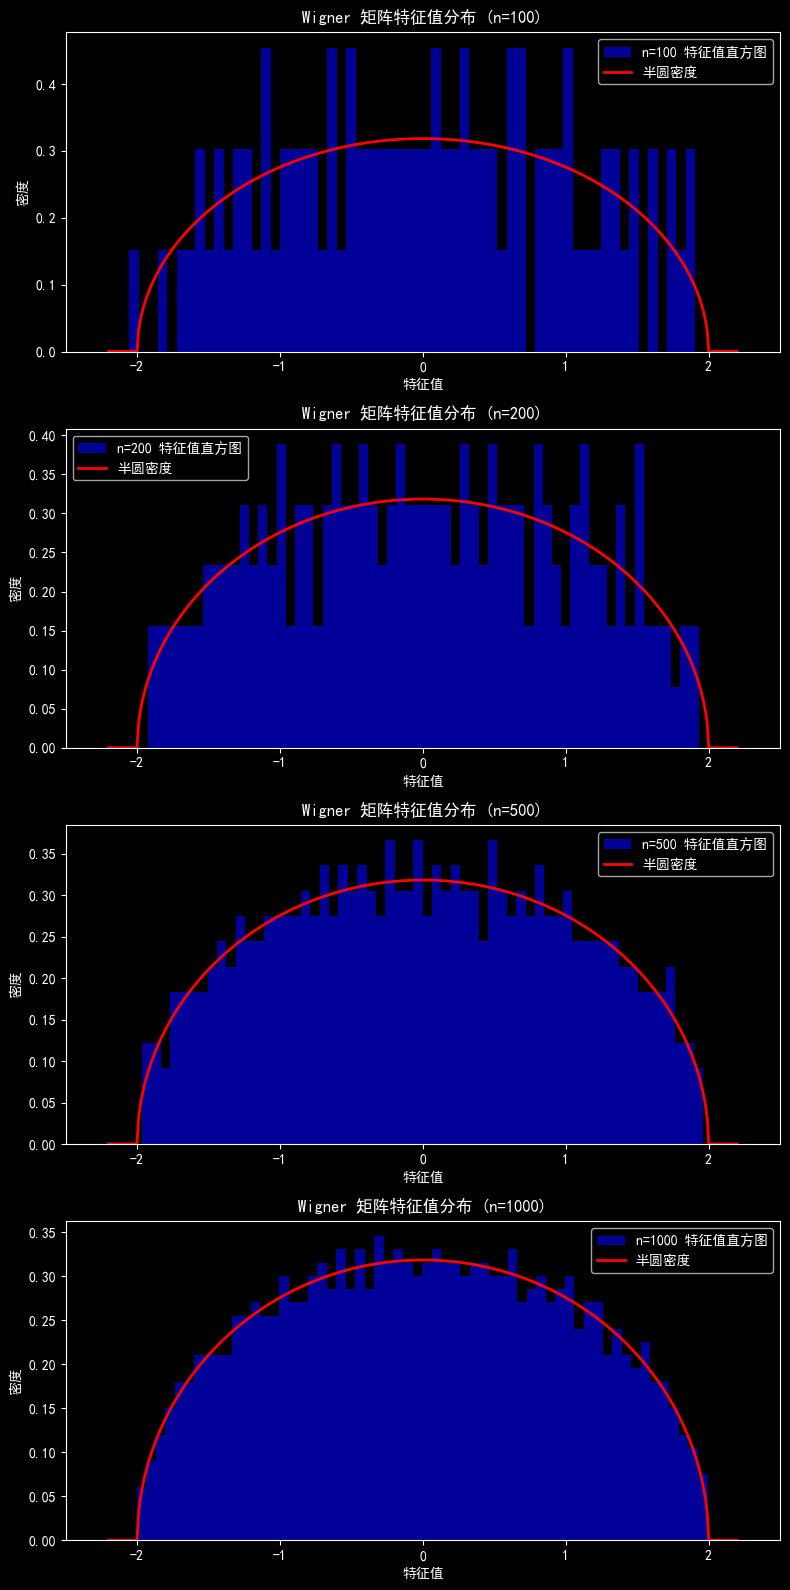


=== Kolmogorov–Smirnov 检验（可选）===
n=  100  KS 统计量=0.1743  p值=0.0040
n=  200  KS 统计量=0.1679  p值=0.0000
n=  500  KS 统计量=0.1629  p值=0.0000
n= 1000  KS 统计量=0.1619  p值=0.0000


In [3]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def wigner_density(x):
    x = np.asarray(x, dtype=float)
    inside = np.abs(x) <= 2
    out = np.zeros_like(x, dtype=float)
    out[inside] = np.sqrt(4.0 - x[inside]**2) / (2.0 * np.pi)
    return out if out.ndim > 0 else float(out)

def generate_wigner(n):
    if not isinstance(n, (int, np.integer)) or isinstance(n, bool):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")
    upper = np.random.normal(0.0, np.sqrt(1.0 / n), size=(n, n))
    tri = np.triu(upper)
    Z = tri + np.triu(upper, 1).T
    return Z

def get_spectrum(matrix):
    return np.linalg.eigvalsh(np.asarray(matrix, dtype=float))

def plot_wigner_spectra(ns=(100, 200, 500, 1000), bins=60):
    fig, axes = plt.subplots(len(ns), 1, figsize=(8, 4 * len(ns)))
    xs = np.linspace(-2.2, 2.2, 400)
    ys = wigner_density(xs)
    for ax, n in zip(axes, ns):
        Z = generate_wigner(n)
        eig = get_spectrum(Z)
        ax.hist(eig, bins=bins, density=True, color="blue",
                alpha=0.6, label=f"n={n} 特征值直方图")
        ax.plot(xs, ys, color="red", lw=2, label="半圆密度")
        ax.set_title(f"Wigner 矩阵特征值分布 (n={n})")
        ax.set_xlabel("特征值")
        ax.set_ylabel("密度")
        ax.set_xlim(-2.5, 2.5)
        ax.legend()
    plt.tight_layout()
    plt.show()

np.random.seed(42)
plot_wigner_spectra()

from scipy.stats import kstest

def semicircle_cdf(x):
    x = np.asarray(x, dtype=float)
    cdf = np.zeros_like(x, dtype=float)
    inside = (x >= -2) & (x <= 2)
    xi = x[inside]
    cdf[inside] = 0.5 + (xi * np.sqrt(4 - xi**2) + 2 * np.arcsin(xi / 2)) / (2 * np.pi)
    cdf[x > 2] = 1.0
    return cdf

print("\n=== Kolmogorov–Smirnov 检验（可选）===")
for n in (100, 200, 500, 1000):
    eig = get_spectrum(generate_wigner(n))
    stat, p = kstest(eig, semicircle_cdf)
    print(f"n={n:5d}  KS 统计量={stat:.4f}  p值={p:.4f}")

Conway 的⽣命游戏

=== 1. is_valid_board 测试 ===
有效棋盘: True
一维数组: False
含非法值: False
非 ndarray: False

=== 2. gol_step 测试（滑翔机 glider）===
初始棋盘:
[[0 1 0 0 0]
 [0 0 1 0 0]
 [1 1 1 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
下一步:
[[0 0 0 0 0]
 [1 0 1 0 0]
 [0 1 1 0 0]
 [0 1 0 0 0]
 [0 0 0 0 0]]

=== 3. 演化 4 步并画图 ===


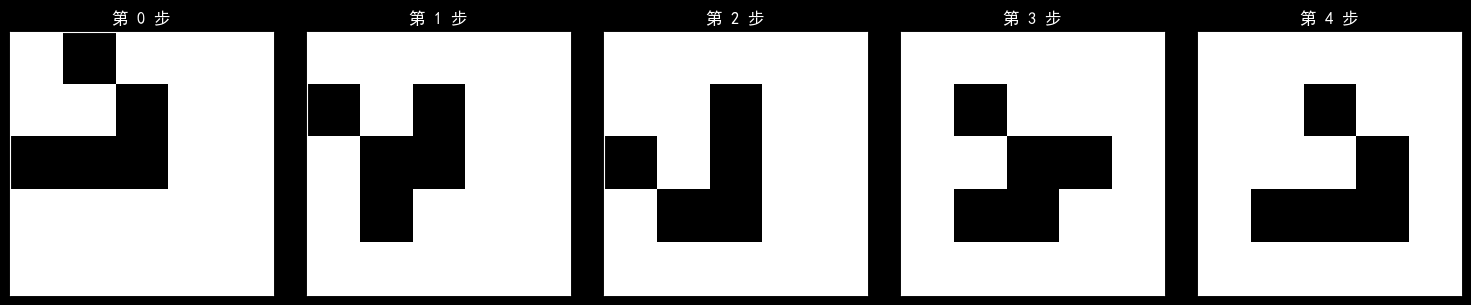


=== 4. draw_gol_board 单独画一帧 ===


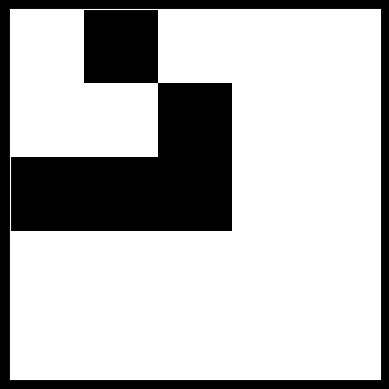

In [5]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    if board.size == 0:
        return False
    return bool(np.all((board == 0) | (board == 1)))

def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("输入不是有效的生命游戏棋盘")
    m, n = board.shape
    neighbors = np.zeros((m, n), dtype=int)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(board, di, axis=0), dj, axis=1)
    new_board = np.zeros((m, n), dtype=int)
    alive = board == 1
    new_board[alive & ((neighbors == 2) | (neighbors == 3))] = 1
    new_board[(~alive) & (neighbors == 3)] = 1
    return new_board

def draw_gol_board(board):
    plt.imshow(board, cmap=plt.get_cmap("gray_r"), interpolation="nearest")
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.show()

# ================= 演示与输出 =================
print("=== 1. is_valid_board 测试 ===")
good = np.array([[0, 1, 0], [1, 1, 0], [0, 0, 1]])
print("有效棋盘:", is_valid_board(good))
print("一维数组:", is_valid_board(np.array([0, 1, 0])))
print("含非法值:", is_valid_board(np.array([[0, 2], [1, 0]])))
print("非 ndarray:", is_valid_board([[0, 1], [1, 0]]))

print("\n=== 2. gol_step 测试（滑翔机 glider）===")
glider = np.array([
    [0, 1, 0, 0, 0],
    [0, 0, 1, 0, 0],
    [1, 1, 1, 0, 0],
    [0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0],
], dtype=int)
print("初始棋盘:")
print(glider)
print("下一步:")
print(gol_step(glider))

print("\n=== 3. 演化 4 步并画图 ===")
board = glider.copy()
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i, ax in enumerate(axes):
    ax.imshow(board, cmap=plt.get_cmap("gray_r"), interpolation="nearest")
    ax.set_title(f"第 {i} 步")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    board = gol_step(board)
plt.tight_layout()
plt.show()

print("\n=== 4. draw_gol_board 单独画一帧 ===")
draw_gol_board(glider)

使⽤ pandas DataFrame

In [9]:
import pandas as pd
df = pd.read_csv(r"D:\ana\Lib\site-packages\sklearn\datasets\data\iris.csv")
print(df.columns)
print(df.head())

Index(['150', '4', 'setosa', 'versicolor', 'virginica'], dtype='object')
   150    4  setosa  versicolor  virginica
0  5.1  3.5     1.4         0.2          0
1  4.9  3.0     1.4         0.2          0
2  4.7  3.2     1.3         0.2          0
3  4.6  3.1     1.5         0.2          0
4  5.0  3.6     1.4         0.2          0


In [10]:
import pandas as pd

df = pd.read_csv(r"D:\ana\Lib\site-packages\sklearn\datasets\data\iris.csv",
                 header=None, skiprows=1)
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "target"]
df["species"] = df["target"].map({0: "setosa", 1: "versicolor", 2: "virginica"})

print("=== 任务1：数据概况 ===")
print("数据点数量:", len(df))
print("\n每列数据类型:")
print(df.dtypes)
print("\n列名:", list(df.columns))
print("\n花卉种类数:", df["species"].nunique())

df.loc[34] = [4.9, 3.1, 1.5, 0.2, 0, "setosa"]
df.loc[37] = [4.9, 3.6, 1.4, 0.1, 0, "setosa"]

print("\n=== 任务2：修正后的两行 ===")
print(df.loc[[34, 37]])

df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]

print("\n=== 任务3：新增列后的前5行 ===")
print(df.head())

df.to_csv("iris_corrected.csv", index=False)
print("\n已保存为 iris_corrected.csv")

agg_result = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print("\n=== 任务5：分组统计 ===")
print(agg_result)

=== 任务1：数据概况 ===
数据点数量: 150

每列数据类型:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
target            int64
species          object
dtype: object

列名: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'target', 'species']

花卉种类数: 3

=== 任务2：修正后的两行 ===
    sepal_length  sepal_width  petal_length  petal_width  target species
34           4.9          3.1           1.5          0.2       0  setosa
37           4.9          3.6           1.4          0.1       0  setosa

=== 任务3：新增列后的前5行 ===
   sepal_length  sepal_width  petal_length  petal_width  target species  \
0           5.1          3.5           1.4          0.2       0  setosa   
1           4.9          3.0           1.4          0.2       0  setosa   
2           4.7          3.2           1.3          0.2       0  setosa   
3           4.6          3.1           1.5          0.2       0  setosa   
4           5.0          3.6           1.4          0.2       0  setos